<a href="https://colab.research.google.com/github/mezbourmalek/signsense/blob/feature%2F1D-CNN-%26-SVM-training/notebooks_model/svm_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/Signsence')

ARRAYS_DIR = PROJECT_DIR / 'arrays'
SPLIT_PATH = PROJECT_DIR / 'splits' / 'split.json'
OUT_DIR    = PROJECT_DIR / 'svm_out'

required = [PROJECT_DIR / 'load_data.py', SPLIT_PATH,
            ARRAYS_DIR / 'X.npy', ARRAYS_DIR / 'y.npy',
            ARRAYS_DIR / 'groups.npy', ARRAYS_DIR / 'hand_frames.npy']
for p in required:
    print(('OK      ' if p.exists() else 'MISSING ') + str(p))
assert all(p.exists() for p in required), 'ملفات ناقصة'

OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK      /content/drive/MyDrive/Signsence/load_data.py
OK      /content/drive/MyDrive/Signsence/splits/split.json
OK      /content/drive/MyDrive/Signsence/arrays/X.npy
OK      /content/drive/MyDrive/Signsence/arrays/y.npy
OK      /content/drive/MyDrive/Signsence/arrays/groups.npy
OK      /content/drive/MyDrive/Signsence/arrays/hand_frames.npy


In [3]:
import json
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from load_data import load_split

MIN_HAND_FRAMES_TRAIN = 0
REFIT_TRAIN_VAL = False

data = load_split(ARRAYS_DIR, split_path=SPLIT_PATH,
                  min_hand_frames_train=MIN_HAND_FRAMES_TRAIN, with_groups=True)
X_tr, y_tr, g_tr = data['train']
X_va, y_va, g_va = data['validation']
X_te, y_te, g_te = data['test']
print(f'train={len(y_tr)}  val={len(y_va)}  test={len(y_te)}')

train=4061  val=796  test=814


In [6]:
print('NaN في X:', np.isnan(X_tr).any(), '| قيم لا نهائية:', np.isinf(X_tr).any())
print('نسبة الأصفار في اليد اليسرى:', (X_tr[:, :, 0:63] == 0).mean().round(3))
print('نسبة الأصفار في اليد اليمنى:', (X_tr[:, :, 63:126] == 0).mean().round(3))
print('نطاق القيم: min', X_tr.min().round(3), '| max', X_tr.max().round(3))

print('\nالفئات في كل قسم:')
for n, y in [('train', y_tr), ('val', y_va), ('test', y_te)]:
    print(n, len(y), np.bincount(y, minlength=15))

print('\nمشاركون مشتركون بين الأقسام:',
      set(g_tr) & set(g_va), set(g_tr) & set(g_te), set(g_va) & set(g_te))

with open(ARRAYS_DIR / 'labels.json', encoding='utf-8') as f:
    print('\nlabels.json:', json.load(f))

NaN في X: False | قيم لا نهائية: False
نسبة الأصفار في اليد اليسرى: 0.66
نسبة الأصفار في اليد اليمنى: 0.579
نطاق القيم: min -5.986 | max 5.012

الفئات في كل قسم:
train 4061 [275 256 273 279 261 248 280 266 273 284 291 265 278 256 276]
val 796 [57 49 54 53 54 45 50 54 55 58 54 50 57 56 50]
test 814 [58 52 57 53 55 53 58 52 60 52 55 53 58 41 57]

مشاركون مشتركون بين الأقسام: set() set() set()

labels.json: {'labels': ['hello', 'thankyou', 'please', 'yes', 'no', 'wait', 'finish', 'where', 'go', 'home', 'drink', 'book', 'airplane', 'car', 'jump'], 'label_to_index': {'hello': 0, 'thankyou': 1, 'please': 2, 'yes': 3, 'no': 4, 'wait': 5, 'finish': 6, 'where': 7, 'go': 8, 'home': 9, 'drink': 10, 'book': 11, 'airplane': 12, 'car': 13, 'jump': 14}}


In [12]:
def hand_features(H):
    N, T, _ = H.shape
    m = (np.abs(H).sum(2) > 0).astype(np.float32)
    P = H.reshape(N, T, 21, 3)
    wrist = P[:, :, 0, :].copy()
    P = P - P[:, :, 0:1, :]
    scale = np.maximum(np.linalg.norm(P, axis=3).max(2), 1e-6)
    Q = (P / scale[:, :, None, None]).reshape(N, T, 63)
    Q = Q * m[..., None]
    mk = m[..., None]

    def mmean(A, M, MK):
        return (A * MK).sum(1) / np.maximum(M.sum(1, keepdims=True), 1)

    cnt = m.sum(1, keepdims=True)
    mean = mmean(Q, m, mk)
    std = np.sqrt(mmean((Q - mean[:, None, :]) ** 2, m, mk))
    feats = [mean, std]
    for part in np.array_split(np.arange(T), 3):
        feats.append(mmean(Q[:, part], m[:, part], mk[:, part]))
    dQ = Q[:, 1:] - Q[:, :-1]
    mm = m[:, 1:] * m[:, :-1]
    feats.append(mmean(np.abs(dQ), mm, mm[..., None]))
    wm = mmean(wrist, m, mk)
    feats.append(np.sqrt(mmean((wrist - wm[:, None, :]) ** 2, m, mk)))
    for part in np.array_split(np.arange(T), 3):
        feats.append(mmean(wrist[:, part], m[:, part], mk[:, part]))
    feats += [cnt / T]
    return np.concatenate(feats, axis=1)

def make_features(X):
    X = X.astype(np.float32)
    pose = X[:, :, 126:144]
    pf = [pose.mean(1), pose.std(1)] + [pose[:, p].mean(1) for p in np.array_split(np.arange(X.shape[1]), 3)]
    return np.concatenate([hand_features(X[:, :, 0:63]),
                           hand_features(X[:, :, 63:126])] + pf, axis=1)

F_tr, F_va, F_te = (make_features(a) for a in (X_tr, X_va, X_te))
print('feature dim:', F_tr.shape[1], '| NaN:', np.isnan(F_tr).any())

def load_label_names(n):
    try:
        with open(ARRAYS_DIR / 'labels.json', encoding='utf-8') as f:
            names = json.load(f)['labels']
        assert len(names) == n
        return [str(x) for x in names]
    except Exception as e:
        print('تحذير:', e)
        return [str(i) for i in range(n)]

names = load_label_names(len(np.unique(y_tr)))
print(names)

feature dim: 872 | NaN: False
['hello', 'thankyou', 'please', 'yes', 'no', 'wait', 'finish', 'where', 'go', 'home', 'drink', 'book', 'airplane', 'car', 'jump']


In [13]:
import time

def quick(F_a, y_a, F_b, y_b, **svm_kw):
    m = Pipeline([('scaler', StandardScaler()),
                  ('pca', PCA(n_components=0.99, random_state=0)),
                  ('svm', SVC(class_weight='balanced', random_state=0, **svm_kw))])
    t = time.time()
    m.fit(F_a, y_a)
    p = m.predict(F_b)
    print(f"{str(svm_kw):45s} Macro-F1={f1_score(y_b, p, average='macro'):.4f} "
          f"Acc={accuracy_score(y_b, p):.4f}  ({time.time()-t:.0f}s)")

for C in (3e-4, 1e-3, 1e-2):
    quick(F_tr, y_tr, F_va, y_va, kernel='linear', C=C)
for C in (1, 10, 100):
    quick(F_tr, y_tr, F_va, y_va, kernel='rbf', C=C, gamma='scale')

{'kernel': 'linear', 'C': 0.0003}             Macro-F1=0.5719 Acc=0.5779  (7s)
{'kernel': 'linear', 'C': 0.001}              Macro-F1=0.6130 Acc=0.6168  (6s)
{'kernel': 'linear', 'C': 0.01}               Macro-F1=0.6374 Acc=0.6394  (2s)
{'kernel': 'rbf', 'C': 1, 'gamma': 'scale'}   Macro-F1=0.6240 Acc=0.6244  (3s)
{'kernel': 'rbf', 'C': 10, 'gamma': 'scale'}  Macro-F1=0.6441 Acc=0.6470  (5s)
{'kernel': 'rbf', 'C': 100, 'gamma': 'scale'} Macro-F1=0.6346 Acc=0.6382  (3s)


In [21]:
# pipe = Pipeline([
#     ('scaler', StandardScaler()),
#     ('pca', PCA(n_components=0.99, random_state=0)),
#     ('svm', SVC(class_weight='balanced', random_state=0)),
# ])

# param_grid = [
#     {'svm__kernel': ['linear'],
#      'svm__C': [0.003, 0.01, 0.03, 0.1]},
#     {'svm__kernel': ['rbf'],
#      'svm__C': [3, 10, 30, 100],
#      'svm__gamma': ['scale', 1e-3, 3e-3]},
# ]

# search = GridSearchCV(pipe, param_grid, scoring='f1_macro',
#                       cv=GroupKFold(n_splits=5), n_jobs=-1, verbose=1, refit=True)
# search.fit(F_tr, y_tr, groups=g_tr)
# print('Best params:', search.best_params_)
# print(f'CV Macro-F1: {search.best_score_:.4f}')

In [16]:
pipe2 = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.99, random_state=0)),
    ('svm', SVC(class_weight='balanced', random_state=0)),
])

param_grid2 = [
    {'svm__kernel': ['rbf'],
     'svm__C': [10, 30, 100, 300],
     'svm__gamma': [1e-4, 3e-4, 1e-3]},
]

search2 = GridSearchCV(pipe2, param_grid2, scoring='f1_macro',
                       cv=GroupKFold(n_splits=5), n_jobs=-1, verbose=1, refit=True)
search2.fit(F_tr, y_tr, groups=g_tr)

print('Best params:', search2.best_params_)
print(f'CV Macro-F1: {search2.best_score_:.4f}')

pred_va2 = search2.predict(F_va)
print(f"[VAL] Macro-F1={f1_score(y_va, pred_va2, average='macro'):.4f} | "
      f"Acc={accuracy_score(y_va, pred_va2):.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best params: {'svm__C': 30, 'svm__gamma': 0.0003, 'svm__kernel': 'rbf'}
CV Macro-F1: 0.7466
[VAL] Macro-F1=0.6489 | Acc=0.6533


In [20]:
# pred_va = search.predict(F_va)
# print(f"[VAL] Macro-F1={f1_score(y_va, pred_va, average='macro'):.4f} | "
#       f"Acc={accuracy_score(y_va, pred_va):.4f}")
# print(classification_report(y_va, pred_va, target_names=names, digits=3))

In [17]:
print(classification_report(y_va, pred_va2, target_names=names, digits=3))

              precision    recall  f1-score   support

       hello      0.632     0.754     0.688        57
    thankyou      0.544     0.633     0.585        49
      please      0.950     0.704     0.809        54
         yes      0.717     0.717     0.717        53
          no      0.603     0.704     0.650        54
        wait      0.554     0.689     0.614        45
      finish      0.733     0.440     0.550        50
       where      0.939     0.574     0.713        54
          go      0.474     0.327     0.387        55
        home      0.647     0.948     0.769        58
       drink      0.500     0.815     0.620        54
        book      0.589     0.660     0.623        50
    airplane      0.932     0.719     0.812        57
         car      0.630     0.518     0.569        56
        jump      0.718     0.560     0.629        50

    accuracy                          0.653       796
   macro avg      0.678     0.651     0.649       796
weighted avg      0.680   

In [18]:
search = search2

[TEST] Macro-F1=0.8027 | Acc=0.8022
              precision    recall  f1-score   support

       hello      0.766     0.845     0.803        58
    thankyou      0.765     0.750     0.757        52
      please      0.946     0.930     0.938        57
         yes      0.810     0.887     0.847        53
          no      0.672     0.709     0.690        55
        wait      0.739     0.642     0.687        53
      finish      0.776     0.897     0.832        58
       where      0.833     0.769     0.800        52
          go      0.778     0.583     0.667        60
        home      0.962     0.962     0.962        52
       drink      0.847     0.909     0.877        55
        book      0.581     0.679     0.626        53
    airplane      0.982     0.931     0.956        58
         car      0.900     0.878     0.889        41
        jump      0.736     0.684     0.709        57

    accuracy                          0.802       814
   macro avg      0.806     0.804     0.803 

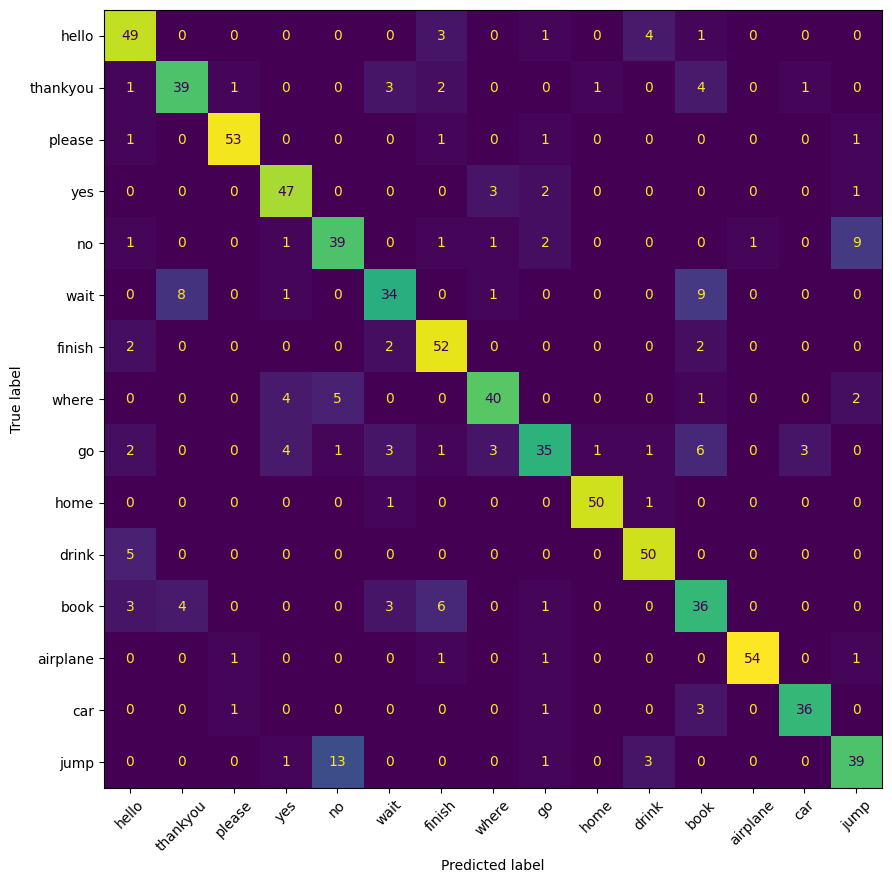

Saved to: /content/drive/MyDrive/Signsence/svm_out


In [19]:
final = search.best_estimator_
if REFIT_TRAIN_VAL:
    final = clone(search.best_estimator_)
    final.fit(np.vstack([F_tr, F_va]), np.concatenate([y_tr, y_va]))

pred_te = final.predict(F_te)
print(f"[TEST] Macro-F1={f1_score(y_te, pred_te, average='macro'):.4f} | "
      f"Acc={accuracy_score(y_te, pred_te):.4f}")
report = classification_report(y_te, pred_te, target_names=names, digits=3)
print(report)

cm = confusion_matrix(y_te, pred_te)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.savefig(OUT_DIR / 'confusion_matrix_test.png', dpi=150)
plt.show()

np.savetxt(OUT_DIR / 'confusion_matrix_test.csv', cm, fmt='%d', delimiter=',')
(OUT_DIR / 'classification_report_test.txt').write_text(report, encoding='utf-8')
joblib.dump({'model': final, 'labels': names, 'params': search.best_params_},
            OUT_DIR / 'svm_model.joblib')
print('Saved to:', OUT_DIR)

In [22]:
from google.colab import files

files.download(str(OUT_DIR / "svm_model.joblib"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
final = search.best_estimator_     # هو search2 إن نفّذت السطر search = search2

for name, F, y in [('Train', F_tr, y_tr),
                   ('Validation', F_va, y_va),
                   ('Test', F_te, y_te)]:
    p = final.predict(F)
    print(f"{name:11s} Accuracy={accuracy_score(y, p):.4f} | "
          f"Macro-F1={f1_score(y, p, average='macro'):.4f}")

Train       Accuracy=0.9813 | Macro-F1=0.9810
Validation  Accuracy=0.6533 | Macro-F1=0.6489
Test        Accuracy=0.8022 | Macro-F1=0.8027


In [24]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    search2.best_estimator_,
    F_tr,
    y_tr,
    groups=g_tr,
    cv=GroupKFold(n_splits=5),
    scoring='f1_macro',
    n_jobs=-1
)

print("Fold scores:", cv_scores)
print("Mean:", cv_scores.mean())
print("Std:", cv_scores.std())

Fold scores: [0.70757425 0.71701779 0.86392038 0.73230935 0.71236437]
Mean: 0.746637226993438
Std: 0.059225807345220864
